# Notebook 2: Where Does Weight Come From? Reliance and Winning Conflicts

Notebook 1 modelled a principle's weight as how often it is invoked, and found a
stable bimodal split. Its honest gap was that invocation frequency is not
Berman's notion of weight. Berman says weight is conferred two ways: a principle
gains weight by **winning conflicts** ("by battle ... by the rules that are
adjudged victorious ... when principles press in opposing directions," JESP
p. 324), and that weight is amplified the more later decisions **rely on** the
precedents that carry it and those precedents remain good law (pp. 322-23). This
notebook implements that mechanism, which the old paper never did without the
model collapsing.

**The mechanism.** A principle earns weight when it is a *dispositive winner* in a
*contested* case (principles genuinely push both ways). That credit is amplified
by how much the deciding precedent is later cited, decays gradually, and is
removed if the precedent is overruled. There is no protective floor, which is
what made the old precedent-stock attempt collapse to equal weights.

**One modelling choice, stated up front.** Battles are decided by a fixed
background structure of how strongly each principle is pressed in cases, not by
the weight being built. Making it literally circular, so that the weight already
accumulated decides who wins the next battle, produces runaway lock-in (a few
principles take everything). We show that lock-in below as the reason for the
choice. Berman's own dynamics are gradual and correctable, not winner-take-all.

**What we look for.** The mechanism should give weight its Berman-faithful
content: a principle's weight should reflect how often it **wins embedded
battles**, not how often it is invoked. The sharp test is dissociation -- a
principle invoked constantly but that always loses should have high invocation
frequency and low conferred weight. We measure that directly, report how the
conferred weights are shaped (graded or bimodal, as a finding, not a requirement
-- Berman permits equal weights), and check them against the requirements R1-R4
from Notebook 0.

**What this does not settle.** It does not model whose decisions count (Berman
makes the recognitional community itself endogenous), statutory as opposed to
judicial embedding, or the way a principle's scope shifts with its weight. And
gradation is reported, never required: Berman permits equal weights, so a bimodal
outcome would be a real finding, not a failure.

## Setup
On Colab this mounts your Google Drive and works inside the project folder so
outputs persist. Run locally, it uses the current folder.

In [14]:
import os
PROJECT = '/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06'
try:
    from google.colab import drive            # on Colab: mount Drive and work in the project folder
    drive.mount('/content/drive')
    os.makedirs(PROJECT, exist_ok=True); os.chdir(PROJECT)
    print('Colab: mounted Drive, working in', os.getcwd())
except ImportError:
    print('Local: working in', os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab: mounted Drive, working in /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06


In [15]:
%%writefile berman_core.py
"""
berman_core.py — shared, corrected core for the Berman Modeling rebuild (2026-06).

ONE source of truth for the SAW model, principle sets, Hart baselines, a *seeded*
bootstrap, the activation generators, the weight-tolerance (critical-sigma)
machinery, and the redesigned evaluation criteria. Every notebook %%writefile's
this file and `from berman_core import *`, so a fix here propagates everywhere
(ends the verbatim-copy drift of the old notebooks).

Design decisions baked in (vs. the old code):
  * Determinacy convention is strict |F| > tau, matching the manuscript.
  * RNG is always explicit (np.random.default_rng(seed)); bootstrap is seeded
    and vectorized, so every CI is reproducible.
  * One determinacy cutoff (DEFAULT_TAU) everywhere — no 0.05-here-0.2-there.
  * Corrected category map: federalism is STRUCTURAL, not moral.
  * Criteria are split into REQUIREMENTS (R1-R4, pass/fail, derived from what
    Berman actually claims) and DESCRIPTIVE measures (D1-D2, reported, never used
    to fail the theory). See CONCEPTUAL_AUDIT_vs_Berman.md.
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List, Optional, Callable, Tuple

import numpy as np

__all__ = [
    "DEFAULT_TAU", "Principle", "NAMED_PRINCIPLES", "CATEGORY_INDEX",
    "make_weights", "named_weight_vector", "category_of",
    "net_force", "is_determinate", "determinacy_rate",
    "random_activations", "category_correlated_activations", "fully_correlated_activations",
    "bootstrap_ci", "critical_sigma", "CRITICAL_SIGMA_CEIL",
    "hart_hierarchical_determinate", "hart_consensus_determinate", "hart_advantage",
    "hart_validation_status",
    "nonlexicality_score", "ordinalize", "saw_verdict", "lexicographic_verdict",
    "weight_cv", "n_survivors", "cluster_gap",
    "METHODOLOGIES", "methodology_tendencies", "LegalSystem",
    "gmm_bimodal", "bimodality_coefficient",
    "RelianceSystem", "weight_entropy", "gini", "n_bins_occupied",
]

# ---------------------------------------------------------------------------
# Determinacy convention
# ---------------------------------------------------------------------------
DEFAULT_TAU: float = 0.20  # a case is determinate when |F| > tau (strict)


# ---------------------------------------------------------------------------
# Principles and categories  (federalism corrected to 'structural')
# ---------------------------------------------------------------------------
@dataclass
class Principle:
    name: str
    weight: float
    category: str = "structural"  # one of: 'textual', 'structural', 'moral'

    def __post_init__(self) -> None:
        assert 0.0 <= self.weight <= 1.0, f"weight out of [0,1]: {self.weight}"
        assert self.category in ("textual", "structural", "moral"), self.category


# The baseline 9-principle set. Order is fixed; categories are the corrected map.
NAMED_PRINCIPLES: List[Tuple[str, str]] = [
    ("text",       "textual"),
    ("original",   "textual"),
    ("precedent",  "structural"),
    ("structure",  "structural"),
    ("federalism", "structural"),   # <-- was grouped with 'moral' in the old code (bug)
    ("dignity",    "moral"),
    ("equality",   "moral"),
    ("liberty",    "moral"),
    ("welfare",    "moral"),
]

CATEGORY_INDEX: Dict[str, List[int]] = {
    cat: [i for i, (_, c) in enumerate(NAMED_PRINCIPLES) if c == cat]
    for cat in ("textual", "structural", "moral")
}


def category_of(i: int) -> str:
    return NAMED_PRINCIPLES[i][1]


# ---------------------------------------------------------------------------
# Weight generators
# ---------------------------------------------------------------------------
def make_weights(n: int, distribution: str, seed: int) -> np.ndarray:
    """Generate n weights. 'uniform' ~U(.60,.70); 'moderate' ~U(.50,.80);
    'high' ~U(.30,.95). Berman's weights are 'rough' (slight..nearly conclusive)."""
    rng = np.random.default_rng(seed)
    if distribution == "uniform":
        return rng.uniform(0.60, 0.70, n)
    if distribution == "moderate":
        return rng.uniform(0.50, 0.80, n)
    if distribution == "high":
        return rng.uniform(0.30, 0.95, n)
    raise ValueError(f"unknown distribution: {distribution}")


def named_weight_vector(distribution: str = "moderate", seed: int = 0) -> np.ndarray:
    """Weights for the 9 NAMED_PRINCIPLES under a given distribution."""
    return make_weights(len(NAMED_PRINCIPLES), distribution, seed)


# ---------------------------------------------------------------------------
# SAW model (nonlexical aggregation)
# ---------------------------------------------------------------------------
def net_force(weights: np.ndarray, activations: np.ndarray) -> np.ndarray:
    """F = sum_i w_i * a_i. Vectorized over a (..., n) activation array."""
    weights = np.asarray(weights, float)
    activations = np.asarray(activations, float)
    return np.sum(weights * activations, axis=-1)


def is_determinate(weights, activations, tau: float = DEFAULT_TAU):
    return np.abs(net_force(weights, activations)) > tau


def determinacy_rate(weights, activation_matrix, tau: float = DEFAULT_TAU) -> float:
    return float(np.mean(is_determinate(weights, activation_matrix, tau)))


# ---------------------------------------------------------------------------
# Activation generators (the conservative independent baseline + realistic structure)
# ---------------------------------------------------------------------------
def random_activations(n_cases: int, n_principles: int, rng: np.random.Generator) -> np.ndarray:
    """Independent activations ~ U(-1, 1). The conservative baseline."""
    return rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))


def category_correlated_activations(n_cases: int, rng: np.random.Generator,
                                    rho: float = 0.7) -> np.ndarray:
    """Activations for the 9 NAMED_PRINCIPLES where principles in the same
    category share a common latent factor (textual together, structural together,
    moral together)."""
    n_p = len(NAMED_PRINCIPLES)
    a = np.empty((n_cases, n_p))
    for cat, idx in CATEGORY_INDEX.items():
        factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
        idio = rng.uniform(-1.0, 1.0, size=(n_cases, len(idx)))
        a[:, idx] = np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)
    return a


def fully_correlated_activations(n_cases: int, n_principles: int,
                                 rng: np.random.Generator, rho: float = 0.7) -> np.ndarray:
    """All principles share one latent factor."""
    factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
    idio = rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))
    return np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)


# ---------------------------------------------------------------------------
# Bootstrap — SEEDED and vectorized (every CI is reproducible)
# ---------------------------------------------------------------------------
def bootstrap_ci(values, n_boot: int = 2000, ci: int = 95, seed: int = 0):
    """Return (mean, lo, hi) for a percentile bootstrap CI on the mean."""
    rng = np.random.default_rng(seed)
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return (float("nan"),) * 3
    means = rng.choice(arr, size=(n_boot, arr.size), replace=True).mean(axis=1)
    lo = float(np.percentile(means, (100 - ci) / 2))
    hi = float(np.percentile(means, 100 - (100 - ci) / 2))
    return float(arr.mean()), lo, hi


# ---------------------------------------------------------------------------
# Weight-uncertainty tolerance: critical sigma  (R2 — "rough weights suffice")
# ---------------------------------------------------------------------------
CRITICAL_SIGMA_CEIL = 1.0  # grid maximum; a returned value == this is right-censored


def critical_sigma(weights: np.ndarray, activation_matrix: np.ndarray,
                   tau: float = DEFAULT_TAU, accuracy: float = 0.80,
                   robust_thresh: float = 0.90, n_mc: int = 64, seed: int = 0,
                   sigma_grid: Optional[np.ndarray] = None) -> float:
    """Smallest weight-noise sigma at which fewer than `accuracy` of cases remain
    individually robust.

    Two-level definition: add N(0, sigma^2) to each weight (clipped to [0,1]); a
    *case* is robust at sigma if it keeps its unperturbed signed VERDICT
    (determinate-for / determinate-against / indeterminate) on at least
    `robust_thresh` of MC draws; sigma* is the smallest sigma at which the
    fraction of robust cases falls below `accuracy`.

    Verdict-stability (not just determinate/indeterminate class) so that a noise
    level that flips a determinate-for case to determinate-against counts as
    instability. The grid runs to CRITICAL_SIGMA_CEIL; a returned value equal to
    the ceiling is right-censored (true tolerance is >= ceiling) -- callers
    should flag these rather than average them as if measured.
    """
    rng = np.random.default_rng(seed)
    w = np.asarray(weights, float)
    A = np.asarray(activation_matrix, float)
    n_p = w.size
    if sigma_grid is None:
        sigma_grid = np.linspace(0.0, CRITICAL_SIGMA_CEIL, 51)

    true_F = A @ w
    true_v = np.sign(true_F); true_v[np.abs(true_F) <= tau] = 0    # (cases,) verdict
    noise = rng.standard_normal((n_mc, A.shape[0], n_p))          # (mc, cases, p)

    prev_sigma, prev_surv = 0.0, 1.0
    for sigma in sigma_grid:
        if sigma == 0:
            prev_sigma, prev_surv = 0.0, 1.0
            continue
        w_noisy = np.clip(w[None, None, :] + sigma * noise, 0.0, 1.0)
        F = np.einsum("mcp,cp->mc", w_noisy, A)                   # (mc, cases)
        v = np.sign(F); v[np.abs(F) <= tau] = 0
        agree_frac = np.mean(v == true_v[None, :], axis=0)        # per case
        survival = float(np.mean(agree_frac >= robust_thresh))
        if survival < accuracy:
            frac = (accuracy - prev_surv) / (survival - prev_surv)
            return float(prev_sigma + frac * (sigma - prev_sigma))
        prev_sigma, prev_surv = sigma, survival
    return float(sigma_grid[-1])  # right-censored at the ceiling


# ---------------------------------------------------------------------------
# Hart baselines  (R4 — "more law than Hart", reported as a margin/curve)
# ---------------------------------------------------------------------------
def hart_consensus_determinate(activations, frac: float = 0.6,
                               act_cut: float = 0.1) -> np.ndarray:
    """Consensus Hart (the faithful operationalization of Hart-as-validation):
    a case is determinate only when the share of *active* principles pointing the
    same direction exceeds `frac`. Hart requires agreement; below `frac` the law
    'runs out'."""
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1)
    neg = np.sum(A < -act_cut, axis=1)
    active = pos + neg
    with np.errstate(invalid="ignore", divide="ignore"):
        share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
    return (active > 0) & (share > frac)


def hart_hierarchical_determinate(weights, activations, tier_of: np.ndarray,
                                  frac: float = 0.6, act_cut: float = 0.1,
                                  tau: float = DEFAULT_TAU) -> np.ndarray:
    """Charitable *lexical-priority* Hart: principles sit in priority tiers
    (0 = top). For each case, the highest-priority tier that has ANY active
    principle is DISPOSITIVE: that tier decides iff its active principles reach
    consensus (>= `frac` agree in sign); otherwise the law runs out. Lower tiers
    are NOT consulted once a higher tier is reached — that is the lexical priority
    Berman's nonlexical model is contrasted against, and it is what stops Hart
    from finding law in nearly every case via tier escape-hatches.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    tier_of = np.asarray(tier_of, int)
    out = np.zeros(A.shape[0], dtype=bool)
    reached = np.zeros(A.shape[0], dtype=bool)  # a dispositive tier has been reached
    for t in np.unique(tier_of):
        idx = np.where(tier_of == t)[0]
        sub = A[:, idx]
        pos = np.sum(sub > act_cut, axis=1)
        neg = np.sum(sub < -act_cut, axis=1)
        active = pos + neg
        this_tier = (active > 0) & (~reached)        # cases first resolved at this tier
        with np.errstate(invalid="ignore", divide="ignore"):
            share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
        out |= this_tier & (share > frac)             # decided iff consensus here (strict, matches consensus Hart)
        reached |= this_tier                           # dispositive; no escape downward
    return out


def hart_validation_status(activations, k: int = 2, act_cut: float = 0.5) -> np.ndarray:
    """Naive validation foil used to make Berman's 'no contradiction' point.

    A direction counts as independently 'validated' when at least `k` principles
    are strongly activated (|a| > act_cut) in that direction. Returns one integer
    code per case:
        0 = gap          (neither direction validated -> the law runs out)
        1 = for          (only the positive direction validated)
        2 = against      (only the negative direction validated)
        3 = contradiction(both directions validated -> q and not-q are both law)

    The point: code 3 is possible for a validation model, but impossible for
    Berman's aggregation, because a single net force has a single sign. So the sum
    never returns code 3.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1) >= k
    neg = np.sum(A < -act_cut, axis=1) >= k
    code = np.zeros(A.shape[0], dtype=int)
    code[pos & ~neg] = 1
    code[neg & ~pos] = 2
    code[pos & neg] = 3
    return code


def hart_advantage(weights, activation_matrix, tier_of, frac: float = 0.6,
                   tau: float = DEFAULT_TAU) -> float:
    """Berman determinacy rate minus hierarchical-Hart determinacy rate (a margin,
    not a pass/fail)."""
    berman = determinacy_rate(weights, activation_matrix, tau)
    hart = float(np.mean(hart_hierarchical_determinate(
        weights, activation_matrix, tier_of, frac=frac, tau=tau)))
    return berman - hart


# ---------------------------------------------------------------------------
# R3 — nonlexicality.  Does determination track activation MAGNITUDES (and many
# principles jointly), as Berman requires, rather than just signs/ranks (lexical)?
# ---------------------------------------------------------------------------
def ordinalize(weights: np.ndarray) -> np.ndarray:
    """Replace weights by rank-based pseudo-weights (1..n)/n — discards cardinal info."""
    order = np.argsort(np.argsort(weights))  # ranks 0..n-1
    return (order + 1) / len(weights)


# Verdict functions return an integer verdict per case: +1 / -1 (determinate for
# / against) or 0 (indeterminate). These are the inputs to the R3 nonlexicality
# probe and are reused by the aggregation-function suite.
def saw_verdict(weights, activation_matrix, tau: float = DEFAULT_TAU) -> np.ndarray:
    """Nonlexical: verdict from the *magnitude-weighted sum* of all principles."""
    F = np.asarray(activation_matrix, float) @ np.asarray(weights, float)
    v = np.sign(F)
    v[np.abs(F) <= tau] = 0
    return v.astype(int)


def lexicographic_verdict(weights, activation_matrix, act_cut: float = 0.05) -> np.ndarray:
    """Lexical: verdict from the SIGN of the single highest-weight active
    principle (Raz exclusionary-reasons style). This is the mode Berman's theory
    is defined against — included only as the lexical foil for the R3 probe."""
    w = np.asarray(weights, float)
    A = np.atleast_2d(np.asarray(activation_matrix, float))
    order = np.argsort(-w)  # highest weight first
    out = np.zeros(A.shape[0], dtype=int)
    decided = np.zeros(A.shape[0], dtype=bool)
    for j in order:
        active = (np.abs(A[:, j]) > act_cut) & (~decided)
        out[active] = np.sign(A[active, j]).astype(int)
        decided |= active
    return out


def nonlexicality_score(verdict_fn: Callable[[np.ndarray], np.ndarray],
                        activation_matrix: np.ndarray,
                        seed: int = 0, n_mc: int = 32, jitter: float = 0.20) -> float:
    """R3 probe. Fraction of cases whose VERDICT changes under a magnitude-only
    perturbation of activations that preserves every activation's sign AND the
    within-case rank order of |activation|.

    A lexical rule (decides on the top-ranked active principle) is invariant to
    such perturbations -> score ~ 0. A genuinely nonlexical, magnitude-aggregating
    rule (SAW) is sensitive -> score > 0. `verdict_fn(A)` maps an (n,9) activation
    matrix to an integer verdict array in {-1,0,+1}.
    """
    rng = np.random.default_rng(seed)
    A = np.asarray(activation_matrix, float)
    base = verdict_fn(A)
    rank = np.argsort(np.argsort(np.abs(A), axis=1), axis=1)  # rank of |a| within row
    n_p = A.shape[1]
    changed = np.zeros(A.shape[0])
    for _ in range(n_mc):
        mag = np.clip(np.abs(A) * (1 + rng.uniform(-jitter, jitter, A.shape)), 0, 1)
        sorted_mag = np.sort(mag, axis=1)
        # Strictly-increasing epsilon breaks ties created when two magnitudes both
        # clip to 1.0; without this, re-placing tied values by index can silently
        # change the rank order (and thus the decision of a lexical rule). This
        # guarantees |A2| keeps the ORIGINAL within-row rank order exactly.
        sorted_mag = sorted_mag + 1e-9 * np.arange(n_p)
        A2 = np.sign(A) * np.take_along_axis(sorted_mag, rank, axis=1)
        changed += (verdict_fn(A2) != base)
    return float(np.mean(changed / n_mc))


# ---------------------------------------------------------------------------
# Descriptive weight statistics (D1 gradation, and emergence diagnostics)
# ---------------------------------------------------------------------------
def weight_cv(weights: np.ndarray) -> float:
    w = np.asarray(weights, float)
    m = w.mean()
    return float(w.std() / m) if m > 0 else 0.0


def n_survivors(weights: np.ndarray, cutoff: float = 0.05) -> int:
    return int(np.sum(np.asarray(weights, float) > cutoff))


def cluster_gap(weights: np.ndarray) -> float:
    """Gap between the two k-means clusters of weights (bimodality diagnostic)."""
    w = np.sort(np.asarray(weights, float))
    if w.size < 2:
        return 0.0
    best = None
    for k in range(1, w.size):
        lo, hi = w[:k], w[k:]
        gap = hi.mean() - lo.mean()
        if best is None or gap > best:
            best = gap
    return float(best)


# ===========================================================================
# Agent-based model of weight emergence (Notebook 1)
# ===========================================================================
# A bench of judges, each carrying an interpretive methodology that sets how
# often it invokes each principle. A principle's emergent "uptake share" is how
# often the bench takes it up across decisions. This is a deliberately simple
# model of Berman's "taking-up" (JESP p. 302); it is NOT his full account of
# weight, which is conferred by reliance and by winning conflicts (pp. 322, 324)
# and is taken up in Notebook 1c. The emergent quantity here is called "uptake
# share," never "weight in Berman's sense."

METHODOLOGIES = ("textualist", "purposivist", "pragmatist", "originalist")

# For each methodology, the principles it tends to invoke often ('high') or
# rarely ('low'); anything unlisted is 'medium'. Names refer to NAMED_PRINCIPLES.
_METH_SETS = {
    "textualist":  {"high": {"text", "original"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
    "purposivist": {"high": {"dignity", "equality", "liberty"},
                    "low":  {"text", "original", "federalism"}},
    "pragmatist":  {"high": {"welfare", "precedent"},
                    "low":  {"dignity", "equality", "original"}},
    "originalist": {"high": {"original", "text", "federalism"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
}

# Invocation-probability ranges (high, medium, low) by how specialized the
# methodologies are. 'wide' = strong specialization (headline); 'narrow' = nearly
# homogeneous (used to show heterogeneity is necessary for the split).
_SPREAD_RANGES = {
    "wide":   ((0.85, 0.95), (0.35, 0.65), (0.02, 0.08)),
    "medium": ((0.70, 0.80), (0.40, 0.60), (0.15, 0.25)),
    "narrow": ((0.60, 0.70), (0.42, 0.58), (0.30, 0.40)),
}


def methodology_tendencies(methodology: str, spread: str, rng) -> np.ndarray:
    """A 9-vector of per-principle invocation probabilities for one judge of a
    given methodology, drawn from the high/medium/low ranges set by `spread`."""
    hi, med, lo = _SPREAD_RANGES[spread]
    sets = _METH_SETS[methodology]
    t = np.empty(len(NAMED_PRINCIPLES))
    for i, (name, _) in enumerate(NAMED_PRINCIPLES):
        rng_range = hi if name in sets["high"] else (lo if name in sets["low"] else med)
        t[i] = rng.uniform(*rng_range)
    return t


class LegalSystem:
    """A bench of judges whose case-by-case invocations produce emergent
    principle uptake-shares.

    `turnover` selects how judges are replaced over time:
      'static'      no replacement (the headline emergence must hold here);
      'fitness'     replace the least decisive 20% with mutated copies of the
                    most decisive 20% (the old, suspect, non-Bermanian rule);
      'appointment' replace a random 20%, reseated from the methodology pool;
      'noise'       replace a random 20% with mutated copies of random judges.
    The point of the four regimes is to show the emergent structure does NOT
    depend on the turnover rule.
    """

    def __init__(self, n_agents=100, methodology_mix=None, spread="wide",
                 use_threshold=True, threshold_pct=50, turnover="static",
                 boost_cut=0.3, learn_from_system=0.15, seed=0):
        # One master seed -> five independent streams. No global np.random.
        ss = np.random.SeedSequence(seed)
        (self._rng_agents, self._rng_panels, self._rng_cases,
         self._rng_dec, self._rng_rep) = (np.random.default_rng(s) for s in ss.spawn(5))
        self.n_agents = n_agents
        self.spread = spread
        self.use_threshold = use_threshold
        self.threshold_pct = threshold_pct
        self.turnover = turnover
        self.boost_cut = boost_cut
        self.learn_from_system = learn_from_system
        self.n_p = len(NAMED_PRINCIPLES)

        # Assign methodologies exactly (round-robin or a given mix), then permute
        # the arrangement with the seeded generator (never np.random.shuffle).
        if methodology_mix is None:
            base = [METHODOLOGIES[i % 4] for i in range(n_agents)]
        else:
            base = []
            for m, frac in methodology_mix.items():
                base += [m] * int(round(frac * n_agents))
            base = (base + [METHODOLOGIES[0]] * n_agents)[:n_agents]
        self.methodology = list(self._rng_agents.permutation(base))
        self.tendencies = np.array([methodology_tendencies(m, spread, self._rng_agents)
                                    for m in self.methodology])     # (n_agents, 9)
        self.system_weights = np.full(self.n_p, 0.5)                # uniform init
        self.raw_uptake = np.full(self.n_p, 0.5)                    # pre-threshold share
        self.success = np.zeros(n_agents)
        self.decisions = np.zeros(n_agents)
        self.trajectory = []

    def _recompute_weights(self, counts, total):
        raw = counts / max(total, 1)
        raw = raw / max(raw.max(), 1e-12)                           # normalize to max
        self.raw_uptake = raw.copy()                               # the pre-threshold vector
        w = raw.copy()
        if self.use_threshold:                                     # zero the bottom percentile
            cut = np.percentile(w, self.threshold_pct)
            w = np.where(w < cut, 0.0, w)
            if w.max() > 0:
                w = w / w.max()
        self.system_weights = w

    def _replace(self, idx_out, idx_template):
        for o, t in zip(idx_out, idx_template):
            self.methodology[o] = self.methodology[t]
            self.tendencies[o] = np.clip(self.tendencies[t] + self._rng_rep.normal(0, 0.03, self.n_p),
                                         0.02, 0.98)
            self.success[o] = 0.0
            self.decisions[o] = 0.0

    def _turnover_step(self):
        k = max(1, int(0.2 * self.n_agents))
        if self.turnover == "static":
            return
        if self.turnover == "fitness":
            # eligible only with >= 5 decisions, so 1-2-case luck cannot rank an agent
            rate = np.where(self.decisions >= 5, self.success / np.maximum(self.decisions, 1), -1.0)
            order = np.argsort(rate)
            self._replace(order[:k], order[-k:])                   # bottom k <- top k
        elif self.turnover == "appointment":
            for o in self._rng_rep.choice(self.n_agents, k, replace=False):
                m = METHODOLOGIES[int(self._rng_rep.integers(4))]
                self.methodology[o] = m
                self.tendencies[o] = methodology_tendencies(m, self.spread, self._rng_rep)
                self.success[o] = 0.0
                self.decisions[o] = 0.0
        elif self.turnover == "noise":
            self._replace(self._rng_rep.choice(self.n_agents, k, replace=False),
                          self._rng_rep.choice(self.n_agents, k, replace=False))

    def simulate(self, n_cases=2000, panel_size=9, update_every=100, selection_every=500):
        counts = np.zeros(self.n_p)
        total = 0
        A = self._rng_cases.uniform(-1, 1, size=(n_cases, self.n_p))           # case stream up front
        panels = np.array([self._rng_panels.choice(self.n_agents, panel_size, replace=False)
                           for _ in range(n_cases)])
        self.trajectory = []
        for c in range(n_cases):
            a = A[c]
            panel = panels[c]
            tend = self.tendencies[panel]                                      # (panel, 9)
            prob = 0.85 * tend + self.learn_from_system * self.system_weights[None, :]
            boost = np.abs(a) > self.boost_cut                                 # strong activations invoked more
            prob = np.where(boost[None, :], np.minimum(prob * 1.15, 0.99), prob)
            invoked = self._rng_dec.uniform(size=(panel_size, self.n_p)) < prob
            counts += invoked.sum(axis=0)
            total += int(invoked.sum())
            forces = (invoked * self.system_weights[None, :] * a[None, :]).sum(axis=1)  # SAW per judge
            med = np.median(np.abs(forces))
            self.success[panel] += (np.abs(forces) >= med)                     # fitness bookkeeping
            self.decisions[panel] += 1
            if (c + 1) % update_every == 0:
                self._recompute_weights(counts, total)
                # record the smooth pre-threshold uptake for convergence/trajectory
                self.trajectory.append((c + 1, self.raw_uptake.copy()))
            if (c + 1) % selection_every == 0:
                self._turnover_step()
        self._recompute_weights(counts, total)
        return self.system_weights


def gmm_bimodal(values, seed=0, dbic_thresh=10.0):
    """Two-vs-one Gaussian-mixture BIC test for bimodality. Returns
    (dbic, separated, is_bimodal): dbic = BIC(1) - BIC(2) (larger favors two
    components); `separated` requires the two means be at least one larger-
    component SD apart (rejects two overlapping Gaussians). Deterministic."""
    from sklearn.mixture import GaussianMixture
    x = np.asarray(values, float).reshape(-1, 1)
    if len(np.unique(np.round(x, 6))) < 2:
        return 0.0, False, False
    g1 = GaussianMixture(1, random_state=seed, n_init=5).fit(x)
    g2 = GaussianMixture(2, random_state=seed, n_init=5).fit(x)
    dbic = float(g1.bic(x) - g2.bic(x))
    means = g2.means_.ravel()
    sds = np.sqrt(g2.covariances_.ravel())
    separated = bool(abs(means[0] - means[1]) > sds.max())
    return dbic, separated, bool(dbic > dbic_thresh and separated)


def bimodality_coefficient(values):
    """Sarle's bimodality coefficient. > 0.555 suggests bimodality. Underpowered
    for very small n, so use it on pooled data, not a single 9-vector."""
    from scipy import stats as _st
    x = np.asarray(values, float)
    n = x.size
    if n < 4:
        return float("nan")
    g = _st.skew(x); k = _st.kurtosis(x, fisher=True)
    return float((g**2 + 1) / (k + 3 * (n - 1)**2 / ((n - 2) * (n - 3))))


# ===========================================================================
# Reliance / by-battle weight conferral (Notebook 2)
# ===========================================================================
# Berman's conferred weight (JESP pp. 322, 324): a principle gains weight by
# winning CONTESTED, DISPOSITIVE battles, amplified by how much the deciding
# precedent is later RELIED UPON (cited), decayed gradually, and removed when a
# precedent is OVERRULED. Battles are decided by a FIXED exogenous "pressure"
# structure (the practice), NOT by the conferred weight being built: making it
# literally circular ("weight made so by battle") produces runaway lock-in, so
# the decision and the read-out are decoupled. There is NO weight floor -- that
# is what made the old "precedent stock" collapse to uniform weights.

def weight_entropy(w):
    """Shannon entropy of a normalized weight vector (higher = more spread)."""
    w = np.asarray(w, float); s = w.sum()
    if s <= 0:
        return 0.0
    p = w / s; p = p[p > 0]
    return float(-(p * np.log(p)).sum())


def gini(w):
    """Gini coefficient of a weight vector (0 = equal, ->1 = concentrated)."""
    w = np.sort(np.asarray(w, float)); n = len(w)
    if w.sum() == 0:
        return 0.0
    return float((2 * np.arange(1, n + 1) - n - 1).dot(w) / (n * w.sum()))


def n_bins_occupied(w, edges=(0.2, 0.4, 0.6, 0.8)):
    """How many of Berman's ~5 rough weight bands a weight vector occupies."""
    return int(len(np.unique(np.digitize(np.asarray(w, float), edges))))


class RelianceSystem:
    """Conferred weight as reliance-amplified, decayed, overruling-prunable
    battle-victories. Battles are decided by `pressure_weights` (fixed), and the
    conferred weight is read out separately, so the dynamics cannot lock in."""

    def __init__(self, pressure_weights=None, invoke_prob=None, salience=None,
                 activations="correlated", cite_mode="similarity", n_cite=3,
                 overrule_rate=0.02, decay_rate=0.9995, clash_cut=0.10,
                 feedback_alpha=0.0, tau=DEFAULT_TAU, seed=0):
        # feedback_alpha > 0 feeds the running conferred weight back into the
        # battle decision (the literally-circular "made so by battle"). It exists
        # only to DEMONSTRATE the runaway lock-in that justifies the decoupled
        # design; the headline runs use feedback_alpha = 0.
        ss = np.random.SeedSequence(seed)
        (self._rng_cases, self._rng_cite, self._rng_over,
         self._rng_inv, self._rng_setup) = (np.random.default_rng(s) for s in ss.spawn(5))
        n_p = len(NAMED_PRINCIPLES)
        self.n_p = n_p
        self.pressure_weights = (named_weight_vector("high", seed) if pressure_weights is None
                                 else np.asarray(pressure_weights, float))
        # uptake invocation propensity. It tracks the same exogenous PRESSURE
        # structure that decides battles (a principle pressed harder is invoked
        # more and can win more), so uptake and conferred weight are correlated
        # but distinct. It is NOT a function of the conferred weight being built,
        # so the two can still come apart (the forced-loser demo overrides it).
        self.invoke_prob = (np.clip(0.2 + 0.7 * (self.pressure_weights / self.pressure_weights.max())
                                    + self._rng_setup.normal(0, 0.05, n_p), 0.05, 0.98)
                            if invoke_prob is None else np.asarray(invoke_prob, float))
        self.salience = np.ones(n_p) if salience is None else np.asarray(salience, float)
        self.activations, self.cite_mode, self.n_cite = activations, cite_mode, n_cite
        self.overrule_rate, self.decay_rate, self.clash_cut, self.tau = \
            overrule_rate, decay_rate, clash_cut, tau
        self.feedback_alpha = feedback_alpha
        self.invoked_total = np.zeros(n_p)
        self.n_seen = 0
        self._ns = 0

    def run(self, n_cases=2000):
        np_ = self.n_p
        A = (category_correlated_activations(n_cases, self._rng_cases) if self.activations == "correlated"
             else random_activations(n_cases, np_, self._rng_cases))
        A = np.clip(A * self.salience[None, :], -1, 1)
        inv = self._rng_inv.uniform(size=(n_cases, np_))
        act = np.zeros((n_cases, np_)); winners = np.zeros((n_cases, np_), bool)
        verdict = np.zeros(n_cases); margin = np.zeros(n_cases); opposing = np.zeros(n_cases)
        contested = np.zeros(n_cases, bool); cc = np.zeros(n_cases)
        good = np.zeros(n_cases, bool); born = np.zeros(n_cases, int); nrm = np.zeros(n_cases)
        ns = 0
        eff = self.pressure_weights.copy()                        # effective decision pressure
        for c in range(n_cases):
            a = A[c]
            self.invoked_total += (inv[c] < self.invoke_prob)     # uptake (weight-independent)
            self.n_seen += 1
            contrib = eff * a
            F = contrib.sum()
            if abs(F) <= self.tau:
                continue                                          # equipoise: no victor
            v = 1.0 if F > 0 else -1.0
            big = np.abs(contrib) > self.clash_cut
            win = (np.sign(contrib) == v) & big                  # dispositive winners only
            cont = bool((contrib > self.clash_cut).any() and (contrib < -self.clash_cut).any())
            opp = float(np.abs(contrib[(np.sign(contrib) != v) & big]).sum())
            act[ns] = a; winners[ns] = win; verdict[ns] = v; margin[ns] = abs(F)
            opposing[ns] = opp; contested[ns] = cont; born[ns] = c
            nrm[ns] = np.linalg.norm(a); good[ns] = True
            if ns > 0:                                           # reliance: cite prior good precedents
                gi = np.where(good[:ns])[0]
                if len(gi):
                    if self.cite_mode == "preferential":
                        order = gi[np.argsort(-cc[gi])]
                    elif self.cite_mode == "random":
                        order = self._rng_cite.permutation(gi)
                    else:                                        # similarity / blended (cosine of facts)
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        score = sims * (1 + cc[gi]) if self.cite_mode == "blended" else sims
                        order = gi[np.argsort(-score)]
                    cc[order[:self.n_cite]] += 1
                    if self._rng_over.uniform() < self.overrule_rate:   # overrule a contradictory good precedent
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        cand = gi[(verdict[gi] == -v) & (sims > 0.5)]
                        if len(cand):
                            good[cand[0]] = False
            ns += 1
            if self.feedback_alpha > 0 and (c + 1) % 100 == 0 and ns > 0:
                mm = good[:ns] & contested[:ns]                   # lock-in demo: feed weight back into decisions
                if mm.any():
                    dec = self.decay_rate ** ((c + 1) - born[:ns][mm])
                    eq = opposing[:ns][mm] / (margin[:ns][mm] + opposing[:ns][mm] + 1e-9)
                    amp = margin[:ns][mm] * (1 + cc[:ns][mm]) * eq * dec
                    cur = (amp[:, None] * winners[:ns][mm]).sum(axis=0)
                    if cur.max() > 0:
                        eff = (1 - self.feedback_alpha) * self.pressure_weights + \
                              self.feedback_alpha * (cur / cur.max())
        self._act, self._winners, self._verdict = act[:ns], winners[:ns], verdict[:ns]
        self._margin, self._opposing, self._contested = margin[:ns], opposing[:ns], contested[:ns]
        self._cc, self._good, self._born = cc[:ns], good[:ns], born[:ns]
        self._n_cases, self._ns = n_cases, ns
        return self.read_weights()

    def _readout(self, use_reliance=True, use_equipoise=True):
        if self._ns == 0:
            return np.zeros(self.n_p)
        m = self._good & self._contested
        if not m.any():
            return np.zeros(self.n_p)
        decay = self.decay_rate ** (self._n_cases - self._born[m])
        equ = (self._opposing[m] / (self._margin[m] + self._opposing[m] + 1e-9)) if use_equipoise else 1.0
        rel = (1 + self._cc[m]) if use_reliance else 1.0
        amp = self._margin[m] * rel * equ * decay
        conf = (amp[:, None] * self._winners[m]).sum(axis=0)
        mx = conf.max()
        return conf / mx if mx > 0 else conf

    def read_weights(self):
        return self._readout(True, True)

    def read_weights_no_reliance(self):
        return self._readout(False, True)

    @property
    def uptake_share(self):
        return self.invoked_total / max(self.n_seen, 1)


if __name__ == "__main__":
    # quick self-test: static properties
    rng = np.random.default_rng(0)
    w = named_weight_vector("moderate", seed=0)
    A = random_activations(2000, 9, rng)
    print("categories:", CATEGORY_INDEX)
    print("determinacy rate (tau=0.2):", round(determinacy_rate(w, A), 4))
    print("critical sigma:", round(critical_sigma(w, A), 4))
    print("nonlexicality SAW vs lexical:",
          round(nonlexicality_score(lambda X: saw_verdict(w, X), A), 4),
          round(nonlexicality_score(lambda X: lexicographic_verdict(w, X), A), 4))
    # quick self-test: ABM emergence
    sysm = LegalSystem(turnover="static", seed=0)
    we = sysm.simulate(n_cases=2000)
    print("\nABM emergent uptake (post-threshold):", np.round(we, 2))
    print("ABM raw uptake (pre-threshold):", np.round(sysm.raw_uptake, 2))
    print("emerged (!= uniform):", not np.allclose(sysm.raw_uptake, 0.5))
    print("raw-uptake bimodal (GMM):", gmm_bimodal(sysm.raw_uptake))
    print("cluster gap:", round(cluster_gap(sysm.raw_uptake), 3), "| CV:", round(weight_cv(sysm.raw_uptake), 3))


Overwriting berman_core.py


In [16]:
import os, json
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from berman_core import *

OUTDIR = os.environ.get('BERMAN_OUTDIR', 'data/notebook2'); os.makedirs(OUTDIR, exist_ok=True)
FIGDIR = os.environ.get('BERMAN_FIGDIR', 'figures'); os.makedirs(FIGDIR, exist_ok=True)
summary = {}
SEEDS, N_CASES = 30, 2000
PRINCIPLE_NAMES = [n for n, _ in NAMED_PRINCIPLES]
print('Core loaded.')

Core loaded.


In [17]:
# Reference values for the self-check (set from the first verified run).
REF_CV=0.241; REF_GAP=0.354; REF_DBIC_CONF=206.1; REF_DBIC_UPTAKE=215.7; REF_LOSER_UPTAKE=0.949; REF_LOSER_CONF=0.0; REF_SIGMA=0.097

## Experiment 1 - The shape of conferred weight, and why we decouple

We run the reliance mechanism on 2,000 cases for 30 seeds and read off the
conferred weights, then compare their shape to Notebook 1's invocation-uptake,
computed the same way. We also run the locked-in (circular) variant, where the
weight already accumulated decides the next battle, to show why the model keeps
the two separate. As in Notebook 1 the formal bimodality test is on the pooled
distribution; nine points per run is too few to resolve two clusters.

In [18]:
CONF = {}
rows = []
for s in range(SEEDS):
    R = RelianceSystem(activations='correlated', seed=s)
    w = R.run(N_CASES); CONF[s] = w.copy()
    rec = dict(seed=s, cv=weight_cv(w), gap=cluster_gap(w), entropy=weight_entropy(w),
               gini=gini(w), n_bins=n_bins_occupied(w), gmm_dbic=gmm_bimodal(w)[0])
    for i, nm in enumerate(PRINCIPLE_NAMES): rec['conf_' + nm] = w[i]
    rows.append(rec)
df1 = pd.DataFrame(rows); df1.to_csv(f'{OUTDIR}/exp1_emergence.csv', index=False)

# pooled conferred weight vs Notebook 1's pooled invocation-uptake (recomputed here, self-contained)
conf_pooled = np.array([CONF[s] for s in range(SEEDS)]).ravel()
up = []
for s in range(SEEDS):
    m = LegalSystem(turnover='static', use_threshold=True, threshold_pct=50, spread='wide', seed=s); m.simulate(N_CASES)
    up.append(m.raw_uptake)                       # Notebook 1's headline uptake, computed identically
uptake_pooled = np.array(up).ravel()
db_conf = gmm_bimodal(conf_pooled); db_up = gmm_bimodal(uptake_pooled)

# lock-in demonstration: feed the conferred weight back into the battle decision
lock = [(weight_cv(w2), cluster_gap(w2)) for w2 in
        (RelianceSystem(feedback_alpha=1.0, seed=s).run(N_CASES) for s in range(10))]
lock = np.array(lock)

summary['exp1'] = dict(mean_cv=float(df1.cv.mean()), mean_gap=float(df1.gap.mean()),
    mean_entropy=float(df1.entropy.mean()), mean_bins=float(df1.n_bins.mean()),
    per_seed_bimodal=int((df1.gmm_dbic > 10).sum()),
    pooled_dbic_conferred=db_conf[0], pooled_dbic_uptake=db_up[0],
    lockin_cv=float(lock[:, 0].mean()), lockin_gap=float(lock[:, 1].mean()))
print(f'Conferred weight: CV={df1.cv.mean():.3f}, gap={df1.gap.mean():.3f}, entropy={df1.entropy.mean():.3f}, bins={df1.n_bins.mean():.1f}')
print(f'Bimodality (pooled GMM dBIC): conferred={db_conf[0]:.0f}  vs  uptake={db_up[0]:.0f}  -> about as graded as uptake, not more')
print(f'Lock-in variant (circular): CV={lock[:,0].mean():.3f}, gap={lock[:,1].mean():.3f}  (vs decoupled CV={df1.cv.mean():.3f}, gap={df1.gap.mean():.3f})')

Conferred weight: CV=0.241, gap=0.354, entropy=2.165, bins=2.7
Bimodality (pooled GMM dBIC): conferred=206  vs  uptake=216  -> about as graded as uptake, not more
Lock-in variant (circular): CV=0.465, gap=0.594  (vs decoupled CV=0.241, gap=0.354)


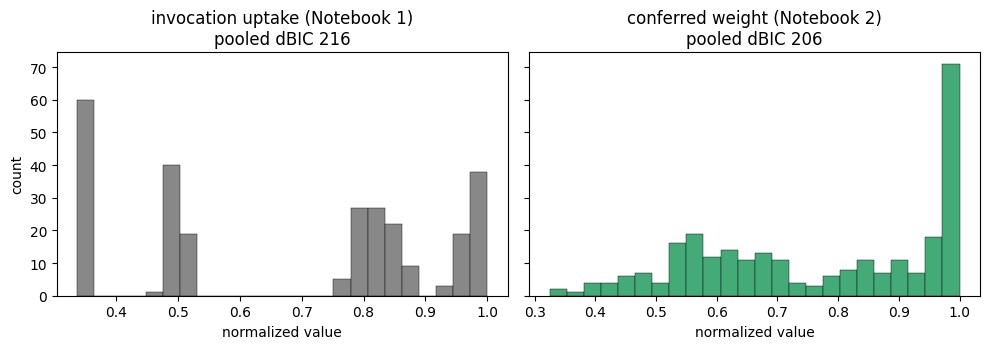

In [19]:
# Diagnostic: pooled histograms, conferred weight vs invocation-uptake
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
ax[0].hist(uptake_pooled, bins=24, color='#888', edgecolor='k', linewidth=0.3)
ax[0].set_title(f'invocation uptake (Notebook 1)\npooled dBIC {db_up[0]:.0f}'); ax[0].set_xlabel('normalized value')
ax[1].hist(conf_pooled, bins=24, color='#4a7', edgecolor='k', linewidth=0.3)
ax[1].set_title(f'conferred weight (Notebook 2)\npooled dBIC {db_conf[0]:.0f}'); ax[1].set_xlabel('normalized value')
ax[0].set_ylabel('count'); fig.tight_layout(); fig.savefig(f'{FIGDIR}/nb2_exp1_graded_vs_bimodal.png', dpi=150); plt.show()

*Reading.* Conferred weight is about as graded as invocation uptake: the pooled
two-cluster evidence is similar for both, and so is the entropy. Reliance does
not, on its own, make weights more graded than counting invocations does. This is
a finding, not a failure: Berman's examples use varied weights but he permits
equal ones, so the mechanism is not required to spread them, and the difference
reliance makes is not in the shape of the distribution but in which principles get
the weight, shown next. The locked-in variant, where accumulated weight decides
the next battle, instead concentrates into a few winners (much higher CV and
gap), which is why the model keeps the battle decision separate from the weight it
is building. (The locked-in figure is a ten-seed demonstration; the contrast
holds at matched seed counts. The uptake baseline it is compared against is
Notebook 1's headline operationalization, which is the conservative choice -- a
less graded baseline would only widen the apparent difference.)

## Experiment 2 - Weight comes apart from invocation, where Berman predicts

Berman's clearest test: a principle invoked constantly but that always loses
should have high invocation frequency and low conferred weight. We construct
exactly that principle (invoked almost every case, but pressed so weakly that it
can never carry a contested clash, so it never registers as a dispositive winner)
and read off both quantities on the same stream. The invocation count is defined
exactly as in Notebook 1, separately from any weight, so the two cannot agree by
construction.

In [20]:
loser = PRINCIPLE_NAMES.index('dignity')      # the principle we force to be a loud loser
pw = named_weight_vector('high', 0).copy(); pw[loser] = 0.05    # tiny pressure -> never wins a clash
ipr = np.full(9, 0.40); ipr[loser] = 0.95                      # invoked almost every case
R = RelianceSystem(pressure_weights=pw, invoke_prob=ipr, seed=0)
w = R.run(N_CASES); u = R.uptake_share
df2 = pd.DataFrame(dict(principle=PRINCIPLE_NAMES, uptake=u, conferred=w,
                        is_loser=[p == 'dignity' for p in PRINCIPLE_NAMES]))
df2.to_csv(f'{OUTDIR}/exp2_dissociation.csv', index=False)
summary['exp2'] = dict(loser_uptake=float(u[loser]), loser_conferred=float(w[loser]),
    max_conferred=float(w.max()), spearman_uptake_conferred=float(stats.spearmanr(u, w).correlation))
print(f"forced loser 'dignity': uptake={u[loser]:.2f} (high)  conferred={w[loser]:.2f} (low)  max conferred={w.max():.2f}")
print(f'Spearman across these 9 in this rigged config = {stats.spearmanr(u, w).correlation:+.2f}  '
      '(driven by the single loser point; the other 8 are pinned at uptake ~0.40 by construction. '
      'The unrigged system-level estimate is in Experiment 4.)')

forced loser 'dignity': uptake=0.95 (high)  conferred=0.00 (low)  max conferred=1.00
Spearman across these 9 in this rigged config = -0.32  (driven by the single loser point; the other 8 are pinned at uptake ~0.40 by construction. The unrigged system-level estimate is in Experiment 4.)


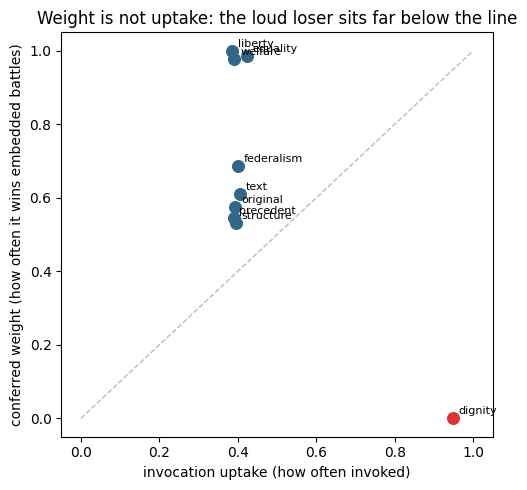

In [21]:
# Money figure: invocation uptake (x) vs conferred weight (y), one point per principle
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], '--', color='#bbb', lw=1)
for i, nm in enumerate(PRINCIPLE_NAMES):
    c = '#d33' if nm == 'dignity' else '#368'
    ax.scatter(u[i], w[i], s=70, color=c, zorder=3)
    ax.annotate(nm, (u[i], w[i]), fontsize=8, xytext=(4, 3), textcoords='offset points')
ax.set_xlabel('invocation uptake (how often invoked)'); ax.set_ylabel('conferred weight (how often it wins embedded battles)')
ax.set_title('Weight is not uptake: the loud loser sits far below the line')
fig.tight_layout(); fig.savefig(f'{FIGDIR}/nb2_exp2_dissociation.png', dpi=150); plt.show()

*Reading.* The forced loser is invoked in almost every case yet carries almost no
conferred weight, while the higher-pressure principles carry the most. The two
quantities are different, and they diverge exactly where Berman says they should.
(The negative Spearman printed above is an artifact of this rigged construction,
where eight principles are pinned at the same invocation rate; the unrigged
system-level relationship is the modest positive one in Experiment 4.) This is
the gap Notebook 1 flagged, closed: invocation frequency is uptake; weight is
winning embedded battles.

## Experiment 3 - Do the conferred weights satisfy R1-R4?

A more faithful mechanism is only useful if its weights still work. We run the
conferred weights from Experiment 1 through the same requirements as Notebook 0
and Notebook 1, on the same kind of fresh held-out cases, so the numbers are
directly comparable.

In [22]:
tier_of = np.array([{'textual': 0, 'structural': 1, 'moral': 2}[c] for _, c in NAMED_PRINCIPLES])
rows = []
for s in range(SEEDS):
    w = CONF[s]
    A = random_activations(800, 9, np.random.default_rng(9000 + s))
    sig = critical_sigma(w, A, n_mc=40, seed=s)
    nl_saw = nonlexicality_score(lambda X: saw_verdict(w, X), A, seed=s)
    nl_lex = nonlexicality_score(lambda X: lexicographic_verdict(w, X), A, seed=s)
    margin = hart_advantage(w, A, tier_of)
    rows.append(dict(seed=s, sigma=sig, hart_margin=margin, n_live=n_survivors(w, 0.05),
        weight_cv=weight_cv(w), entropy=weight_entropy(w), n_bins=n_bins_occupied(w),
        R1=int(n_survivors(w, 0.05) >= 2), R2=int(sig >= 0.07),
        R3=int(nl_saw > 5 * max(nl_lex, 1e-9)), R4=int(margin > 0)))
df3 = pd.DataFrame(rows); df3.to_csv(f'{OUTDIR}/exp3_crossval.csv', index=False)
summary['exp3'] = dict(R1=float(df3.R1.mean()), R2=float(df3.R2.mean()), R3=float(df3.R3.mean()),
    R4=float(df3.R4.mean()), mean_sigma=float(df3.sigma.mean()), mean_margin=float(df3.hart_margin.mean()),
    mean_cv=float(df3.weight_cv.mean()), mean_entropy=float(df3.entropy.mean()))
print('Conferred-weight pass rates (fraction of seeds):')
print(f"  R1={df3.R1.mean():.2f}  R2={df3.R2.mean():.2f}  R3={df3.R3.mean():.2f}  R4={df3.R4.mean():.2f}")
print(f"  mean critical sigma={df3.sigma.mean():.3f} (NB1 0.096, NB0 0.090) | mean Hart margin={df3.hart_margin.mean():+.3f} | D1 cv={df3.weight_cv.mean():.3f} entropy={df3.entropy.mean():.3f}")

Conferred-weight pass rates (fraction of seeds):
  R1=1.00  R2=1.00  R3=1.00  R4=1.00
  mean critical sigma=0.097 (NB1 0.096, NB0 0.090) | mean Hart margin=+0.291 | D1 cv=0.241 entropy=2.165


*Reading.* The conferred weights pass R1-R4: well-defined, tolerant of noise,
nonlexical, and more determinate than a lexical-priority Hart. The gradation (D1)
is reported as a descriptive property, never as a pass or fail. So the more
faithful mechanism is not bought at a cost in usability. Of the four, R2 (noise
tolerance) is the closest call -- the weakest seed clears the floor by a small
margin -- so it is the one to recheck if the configuration changes.

## Experiment 4 - Weight versus uptake across the whole bench

Experiment 2 made the point on one constructed principle. Here we make it at the
system level: across all nine principles and thirty seeds, how far apart are
conferred weight and invocation uptake, and which principles rise or fall when you
switch from counting invocations to counting won battles?

In [23]:
rows = []; rank_shift = np.zeros(9)
for s in range(SEEDS):
    R = RelianceSystem(seed=s); w = R.run(N_CASES); u = R.uptake_share
    rows.append(dict(seed=s, spearman=float(stats.spearmanr(u, w).correlation),
                     pearson=float(np.corrcoef(u, w)[0, 1])))
    rank_shift += (np.argsort(np.argsort(w)) - np.argsort(np.argsort(u)))
df4 = pd.DataFrame(rows); df4.to_csv(f'{OUTDIR}/exp4_uptake_vs_reliance.csv', index=False)
rank_shift /= SEEDS
summary['exp4'] = dict(mean_spearman=float(df4.spearman.mean()), mean_pearson=float(df4.pearson.mean()),
    rank_shift={PRINCIPLE_NAMES[i]: float(rank_shift[i]) for i in range(9)})
print(f'conferred vs uptake on the same stream: Spearman={df4.spearman.mean():+.2f}, Pearson={df4.pearson.mean():+.2f}')
print('mean rank shift (+ rises on weight vs uptake):', {PRINCIPLE_NAMES[i]: round(rank_shift[i], 1) for i in range(9)})

conferred vs uptake on the same stream: Spearman=+0.48, Pearson=+0.39
mean rank shift (+ rises on weight vs uptake): {'text': np.float64(-2.7), 'original': np.float64(-2.4), 'precedent': np.float64(-0.8), 'structure': np.float64(-0.9), 'federalism': np.float64(-1.2), 'dignity': np.float64(1.7), 'equality': np.float64(2.2), 'liberty': np.float64(2.3), 'welfare': np.float64(1.9)}


*Reading.* Conferred weight and invocation uptake are correlated but clearly
distinct quantities across the whole bench: they share some of the live/dead
skeleton but reorder which principles matter, because winning embedded battles is
not the same as being mentioned. The rank shifts show which principles are loud
losers (high uptake, low weight) and which are quiet winners.

In [24]:
json.dump(summary, open(f'{OUTDIR}/notebook2_summary.json', 'w'), indent=2)
print(json.dumps(summary, indent=2)[:1200])

{
  "exp1": {
    "mean_cv": 0.2409869090609716,
    "mean_gap": 0.35404375464898163,
    "mean_entropy": 2.1646260657830974,
    "mean_bins": 2.7,
    "per_seed_bimodal": 9,
    "pooled_dbic_conferred": 206.08254957027384,
    "pooled_dbic_uptake": 215.72438784575922,
    "lockin_cv": 0.46468175675364565,
    "lockin_gap": 0.5935128855168127
  },
  "exp2": {
    "loser_uptake": 0.949,
    "loser_conferred": 0.0,
    "max_conferred": 1.0,
    "spearman_uptake_conferred": -0.31666666666666665
  },
  "exp3": {
    "R1": 1.0,
    "R2": 1.0,
    "R3": 1.0,
    "R4": 1.0,
    "mean_sigma": 0.09744845251426247,
    "mean_margin": 0.29137500000000005,
    "mean_cv": 0.2409869090609716,
    "mean_entropy": 2.1646260657830974
  },
  "exp4": {
    "mean_spearman": 0.48089506199912885,
    "mean_pearson": 0.39356319544811147,
    "rank_shift": {
      "text": -2.7,
      "original": -2.433333333333333,
      "precedent": -0.8333333333333334,
      "structure": -0.9333333333333333,
      "federali

## Self-check
Re-derives the soundness properties and compares headline numbers to the committed reference; raises on drift.

## E1b: is the moral lean the mechanism, or the case generator?

Reliance's moral lean is one pole of the centerpiece divergence, so it matters whether it is a
property of the mechanism or of the activation generator it runs on. This cell reports the tier means
under both regimes.

In [25]:
# --- E1b: is reliance's moral lean a property of the mechanism or of the case generator? ---
_PN2 = [p for p, _ in NAMED_PRINCIPLES]
_TI  = {c: [_PN2.index(p) for p in [_PN2[i] for i in CATEGORY_INDEX[c]]] for c in ('textual','structural','moral')}
tier_by_act = {}
for _act in ('correlated', 'independent'):
    _v = []
    for _s in range(4):
        _w = RelianceSystem(activations=_act, seed=_s).run(2000); _w = _w / _w.max()
        _v.append([float(np.mean(_w[_TI[c]])) for c in ('textual','structural','moral')])
    _m = np.mean(_v, axis=0)
    tier_by_act[_act] = dict(textual=float(_m[0]), structural=float(_m[1]), moral=float(_m[2]))
    print(f"  activations={_act:12s} textual {_m[0]:.3f}  structural {_m[1]:.3f}  moral {_m[2]:.3f}")
_c, _i = tier_by_act['correlated'], tier_by_act['independent']
print(f"  moral-over-textual gap: {_c['moral']-_c['textual']:.3f} correlated vs "
      f"{_i['moral']-_i['textual']:.3f} independent")
print('  -> the direction of the lean is robust; its SIZE is largely produced by the correlated generator.')
pd.DataFrame([dict(activations=k, **v) for k, v in tier_by_act.items()]).to_csv(
    f'{OUTDIR}/exp1b_tier_means_by_activation.csv', index=False)
summary['exp1b'] = tier_by_act


  activations=correlated   textual 0.567  structural 0.686  moral 0.963
  activations=independent  textual 0.821  structural 0.838  moral 0.862
  moral-over-textual gap: 0.396 correlated vs 0.041 independent
  -> the direction of the lean is robust; its SIZE is largely produced by the correlated generator.


In [26]:
ok = True
def check(name, cond):
    global ok; ok = ok and bool(cond); print(('PASS' if cond else 'FAIL'), '-', name)

check('core imported, not copied', RelianceSystem.__module__ == 'berman_core' and saw_verdict.__module__ == 'berman_core')
_a = RelianceSystem(seed=7).run(1000); _b = RelianceSystem(seed=7).run(1000)
check('RelianceSystem reproducible', np.array_equal(_a, _b))
check('not uniform / no floor: CV > 0.05', weight_cv(_a) > 0.05)
check('genuine spread (max - min > 0.15)', (_a.max() - _a.min()) > 0.15)
_R = RelianceSystem(seed=7)
check('reliance is live (read != no_reliance)', np.abs(_R.run(1000) - _R.read_weights_no_reliance()).sum() > 0.01)
check('conferred not locked-in (pooled dBIC < 2x uptake)', summary['exp1']['pooled_dbic_conferred'] < 2 * summary['exp1']['pooled_dbic_uptake'])
check('decoupled is NOT locked in (gap < lock-in gap)', summary['exp1']['mean_gap'] < summary['exp1']['lockin_gap'])
check('dissociation: loud loser has high uptake, low weight', summary['exp2']['loser_uptake'] > 0.5 and summary['exp2']['loser_conferred'] < 0.25)
check('nonlexicality metric not leaking (pure lexical == 0)',
      nonlexicality_score(lambda X: lexicographic_verdict(named_weight_vector('moderate',0), X),
                          random_activations(1500,9,np.random.default_rng(0)), seed=1) < 0.01)
check('conferred weights pass R3 and R4', summary['exp3']['R3'] == 1.0 and summary['exp3']['mean_margin'] > 0)
check('single determinacy threshold', DEFAULT_TAU == 0.20)
check('CV ~ ref', abs(summary['exp1']['mean_cv'] - REF_CV) < 0.04)
check('conferred pooled dBIC ~ ref', abs(summary['exp1']['pooled_dbic_conferred'] - REF_DBIC_CONF) < max(0.2*REF_DBIC_CONF, 20))
check('loser conferred ~ ref', abs(summary['exp2']['loser_conferred'] - REF_LOSER_CONF) < 0.1)
check('exp3 mean sigma ~ ref', abs(summary['exp3']['mean_sigma'] - REF_SIGMA) < 0.03)

# E1b: the moral lean under both activation regimes
_c2 = summary['exp1b']['correlated']; _i2 = summary['exp1b']['independent']
check('E1b moral tier leads under BOTH regimes (direction robust)', _c2['moral'] > _c2['textual'] and _i2['moral'] > _i2['textual'])
check('E1b but the gap is far larger under correlation (size is generator-driven)', (_c2['moral']-_c2['textual']) > 3*(_i2['moral']-_i2['textual']))

print('\n' + ('ALL CHECKS PASSED' if ok else 'SOME CHECKS FAILED'))
summary['self_check_passed'] = bool(ok); assert ok, 'self-check failed'

# the summary is written earlier in this notebook, before the experiments added later;
# re-write it here so every experiment and the self-check flag are captured.
import json; json.dump(summary, open(f'{OUTDIR}/notebook2_summary.json', 'w'), indent=2, default=float)


PASS - core imported, not copied
PASS - RelianceSystem reproducible
PASS - not uniform / no floor: CV > 0.05
PASS - genuine spread (max - min > 0.15)
PASS - reliance is live (read != no_reliance)
PASS - conferred not locked-in (pooled dBIC < 2x uptake)
PASS - decoupled is NOT locked in (gap < lock-in gap)
PASS - dissociation: loud loser has high uptake, low weight
PASS - nonlexicality metric not leaking (pure lexical == 0)
PASS - conferred weights pass R3 and R4
PASS - single determinacy threshold
PASS - CV ~ ref
PASS - conferred pooled dBIC ~ ref
PASS - loser conferred ~ ref
PASS - exp3 mean sigma ~ ref
PASS - E1b moral tier leads under BOTH regimes (direction robust)
PASS - E1b but the gap is far larger under correlation (size is generator-driven)

ALL CHECKS PASSED


## What this notebook establishes

Implementing Berman's actual account of weight, conferred by winning contested
battles and amplified by reliance, yields weights that come apart from invocation
frequency exactly where Berman predicts: a principle invoked constantly but always
defeated carries little weight. The conferred weights still satisfy R1-R4. This
closes the gap Notebook 1 left open, that uptake is not weight, by exhibiting the
difference directly. The conferred weights turn out about as graded as uptake, not
more: reliance changes which principles carry weight, not how spread the weights
are.

It does not settle that reliance is the only mechanism, only that it is Berman's
own and the first one implemented without collapse. The decision to decide battles
by a fixed background pressure rather than by the accumulating weight is a
modelling choice, made because the literally circular version locks in; Berman's
dynamics are gradual, so the choice is defensible, but it is a choice. And whose
decisions count, statutory embedding, and the co-evolution of a principle's scope
are left for later work. Notebook 3 places this mechanism beside invocation uptake
and strategic learning and asks which the requirements favour.